# Modelos Matemáticos y Estadísticos Clásicos
## Diplomado en Data Science 2026

---

## Taller 2


**Integrantes**:

- [Tu nombre aquí]



## Caso: Empresa de comercio electrónico

Formas parte del equipo de Data Science de una empresa de comercio electrónico. Un analista del equipo ha estado trabajando en distintos problemas relacionados con operación, tiempos de entrega, riesgo de atraso y planificación de demanda.

Tu tarea **no consiste solamente en ejecutar modelos**. Durante esta evaluación deberás revisar el trabajo del analista, decidir si sus conclusiones son correctas, proponer mejoras cuando corresponda y justificar tus decisiones.

### Objetivos evaluados

Se espera que seas capaz de:

- identificar qué herramienta estadística es apropiada para una pregunta;
- distinguir entre una asociación descriptiva, evidencia estadística y causalidad;
- interpretar correctamente resultados y métricas;
- detectar cuándo una conclusión **sí** está respaldada por los datos y cuándo **no**;
- comparar modelos y justificar cuál utilizarías.

### Importante

- El código de preparación de datos ya está entregado y **no forma parte de la evaluación**.
- Puedes agregar las celdas de código o texto que estimes necesarias.
- Toda conclusión debe estar respaldada por resultados reproducibles en el notebook.
- No se evaluará la cantidad de código, sino la calidad del análisis.

---

#  Preparación de datos

El siguiente código construye una tabla analítica a nivel de pedido a partir de cuatro tablas de origen.

**No es necesario modificar esta sección.**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score,
    mean_absolute_error,
    root_mean_squared_error
)
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

URL_CUSTOMERS = "https://docs.google.com/spreadsheets/d/13l1up9hqmT8a3z1fj7283gEttstJ8tVFHpzxvwHpp4E/export?format=csv"
URL_ORDER_ITEMS = "https://docs.google.com/spreadsheets/d/1QkCG0Mt4GugaG7pRxnnafE3GulXoqUrkdo2sRFlfpCY/export?format=csv"
URL_ORDERS = "https://docs.google.com/spreadsheets/d/17_OkQhApsLwNoXpb8-63cVQ_zwu5uiQXiYZnpWBeEz8/export?format=csv"
URL_PRODUCTS = "https://docs.google.com/spreadsheets/d/1pN4sFbqEaZVuCQpkkDo-IZB7EgqMOyGUMfoZTbRaOo0/export?format=csv"

customers = pd.read_csv(URL_CUSTOMERS)
order_items = pd.read_csv(URL_ORDER_ITEMS)
orders = pd.read_csv(URL_ORDERS)
products = pd.read_csv(URL_PRODUCTS)

print("customers:", customers.shape)
print("order_items:", order_items.shape)
print("orders:", orders.shape)
print("products:", products.shape)


customers: (15150, 5)
order_items: (16767, 7)
orders: (15000, 8)
products: (9208, 9)


In [2]:
for col in [
    "order_item_id",
    "price",
    "freight_value"
]:
    if col in order_items.columns:
        order_items[col] = pd.to_numeric(
            order_items[col],
            errors="coerce"
        )

for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(
            products[col],
            errors="coerce"
        )


# Fechas
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    if col in orders.columns:
        orders[col] = pd.to_datetime(
            orders[col],
            errors="coerce",
            format="mixed"
        )

# Variables geométricas de productos
for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(products[col], errors="coerce")

if all(c in products.columns for c in ["product_length_cm", "product_height_cm", "product_width_cm"]):
    products["product_volume_cm3"] = (
        products["product_length_cm"]
        * products["product_height_cm"]
        * products["product_width_cm"]
    )

# Enriquecer ítems con atributos de producto
items_prod = order_items.merge(
    products[
        [c for c in [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_volume_cm3"
        ] if c in products.columns]
    ],
    on="product_id",
    how="left"
)

# Agregación a nivel de pedido
agg_dict = {
    "n_items": ("order_item_id", "count"),
    "total_price": ("price", "sum"),
    "total_freight": ("freight_value", "sum"),
    "avg_item_price": ("price", "mean"),
    "n_products": ("product_id", "nunique"),
}

if "product_category_name" in items_prod.columns:
    agg_dict["n_categories"] = ("product_category_name", "nunique")
if "product_weight_g" in items_prod.columns:
    agg_dict["total_weight_g"] = ("product_weight_g", "sum")
if "product_volume_cm3" in items_prod.columns:
    agg_dict["total_volume_cm3"] = ("product_volume_cm3", "sum")

order_agg = (
    items_prod
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

# Tabla analítica
df = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(order_agg, on="order_id", how="left")
)

# Variables derivadas
df["purchase_date"] = df["order_purchase_timestamp"].dt.floor("D")
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.day_name()
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["is_weekend_purchase"] = df["order_purchase_timestamp"].dt.dayofweek.ge(5).astype(int)

df["delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

df["days_to_carrier"] = (
    df["order_delivered_carrier_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400


df["remaining_days"] = (
    df["order_estimated_delivery_date"]
    - df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

df["approval_hours"] = (
    df["order_approved_at"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 3600


df["late_delivery"] = np.where(
    df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna(),
    (df["delay_days"] > 0).astype(int),
    np.nan
)

df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)

# Solo pedidos entregados para análisis de tiempos
delivered = df[
    (df["order_status"] == "delivered")
    & df["delivery_days"].notna()
].copy()

print("Tabla analítica:", df.shape)
print("Pedidos entregados:", delivered.shape)

display(delivered.head())


Tabla analítica: (15150, 31)
Pedidos entregados: (14688, 31)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,total_price,total_freight,avg_item_price,n_products,n_categories,total_weight_g,total_volume_cm3,purchase_date,purchase_weekday,purchase_month,is_weekend_purchase,delivery_days,delay_days,days_to_carrier,remaining_days,approval_hours,late_delivery,freight_ratio
0,3b14820d642ea72e95df3289b6539c1c,4248fddd68e3375c24e743290ce2d9fa,delivered,2018-04-02 13:01:06,2018-04-02 13:10:21,2018-04-04 23:42:34,2018-04-12 17:12:13,2018-04-23,a79c62e50e66e1036ba2cb2e5e00aff3,37190,tres pontas,MG,1.000,75.900,19.500,75.900,1.000,1.000,700.000,"6,912.000",2018-04-02,Monday,2018-04,0,10.174,-10.283,2.445,18.012,0.154,0.000,0.257
1,8a795486f112df15565463862960aa40,e093120ffd5c259e2decb4ff5266f0dd,delivered,2018-05-20 20:28:32,2018-05-22 09:36:09,2018-05-22 15:48:00,2018-06-01 11:50:31,2018-05-29,81ec41f3b0c51a9df15c5957140686fa,13084,campinas,SP,1.000,95.900,11.300,95.900,1.000,1.000,"1,400.000","27,000.000",2018-05-20,Sunday,2018-05,1,11.640,3.493,1.805,6.342,37.127,1.000,0.118
2,7aa2471c1e8d0cd89eec9459fde59414,0eb400f3e6d2f08e70d2ab5af9c203f4,delivered,2017-09-18 19:09:52,2017-09-20 02:10:42,2017-09-21 19:37:10,2017-09-27 19:09:10,2017-10-04,c64b0bf5855e1d6ba223d649298c2915,36889,muriae,MG,1.000,81.000,42.710,81.000,1.000,1.000,"18,100.000","4,332.000",2017-09-18,Monday,2017-09,0,9.000,-6.202,3.019,12.183,31.014,0.000,0.527
3,95cf53396116b5dd518b5ba1c11a0bb5,3b2e666d92ce663a2f35ba3a6bb5df6a,delivered,2017-04-21 19:31:13,2017-04-21 19:45:10,2017-04-25 13:08:20,2017-05-04 16:46:54,2017-05-19,4113a7e912e87f632986e0562da140c7,74075,goiania,GO,1.000,59.000,17.840,59.000,1.000,1.000,275.000,"1,936.000",2017-04-21,Friday,2017-04,0,12.886,-14.301,3.734,23.453,0.233,0.000,0.302
4,6c5eb0920626d3ff5588d03d6f2d4936,1b83beaaa59c8cdfe738f7ead2517da8,delivered,2018-03-15 15:22:28,2018-03-17 03:08:57,2018-03-19 21:14:58,2018-05-03 11:29:52,2018-04-30,d69a93bce76b26886f72125e60b01cec,69040,manaus,AM,1.000,69.900,57.040,69.900,1.000,1.000,"1,200.000","21,000.000",2018-03-15,Thursday,2018-03,0,48.838,3.479,4.245,41.115,35.775,1.000,0.816


### Diccionario resumido de la tabla analítica

| Variable | Descripción |
|---|---|
| `order_id` | Identificador del pedido |
| `customer_state` | Estado/región del cliente |
| `purchase_date` | Fecha de compra |
| `purchase_weekday` | Día de la semana de compra |
| `is_weekend_purchase` | 1 si la compra se realizó sábado o domingo |
| `n_items` | Número de ítems del pedido |
| `n_products` | Número de productos distintos |
| `n_categories` | Número de categorías distintas, si está disponible |
| `total_price` | Valor total de los productos |
| `total_freight` | Valor total del despacho |
| `avg_item_price` | Precio promedio de los ítems |
| `total_weight_g` | Peso total aproximado de los productos |
| `total_volume_cm3` | Volumen total aproximado |
| `delivery_days` | Días transcurridos desde compra hasta entrega |
| `delay_days` | Días de diferencia respecto de la fecha comprometida |
| `days_to_carrier` | Número de días transcurridos desde que se realiza la compra hasta que el pedido es entregado al transportista. |
| `remaining_days` | Número de días disponibles entre la entrega del pedido al transportista y la fecha estimada de entrega al cliente. |
| `approval_hours` | Número de horas transcurridas desde que se realiza la compra hasta que el pedido es aprobado. |
| `late_delivery` | 1 si el pedido llegó después de la fecha comprometida |
| `freight_ratio` | Costo de despacho dividido por valor de productos |

---




## Primer bloque (20 puntos)

El analista preparó la siguiente tabla cruzada entre **tamaño del pedido** y **atraso**.

Primero creó dos grupos:

- `1_item`: pedidos con un solo ítem;
- `2_o_mas`: pedidos con dos o más ítems.

In [3]:
analisis_1 = delivered[
    delivered["late_delivery"].notna()
    & delivered["n_items"].notna()
].copy()

analisis_1["grupo_items"] = np.where(
    analisis_1["n_items"] == 1,
    "1_item",
    "2_o_mas"
)

tabla = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"]
)

tabla


late_delivery,0.000,1.000
grupo_items,,
1_item,12054,1080
2_o_mas,1309,96


El analista luego calculó dos tablas:



In [4]:
# Tabla A
tabla_fila = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="index"
)

tabla_fila


late_delivery,0.000,1.000
grupo_items,,
1_item,0.918,0.082
2_o_mas,0.932,0.068


In [5]:
# Tabla B
tabla_columna = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="columns"
)

tabla_columna


late_delivery,0.000,1.000
grupo_items,,
1_item,0.902,0.918
2_o_mas,0.098,0.082



El analista afirma:

> "El analista observa que en la Tabla B el valor asociado a 1_item y late_delivery=1 es 0,918 y concluye que “los pedidos de un ítem tienen 91,8% de probabilidad de atraso”. ¿Es correcta esta interpretación?"


1. Explique qué representa el valor 0,082 de la Tabla A.  

2. Explique qué representa el valor 0,918 de la Tabla B.

3. ¿Cuál de las dos tablas permite comparar la probabilidad de atraso entre
pedidos de 1 ítem y de 2 o más ítems?

4. ¿Los resultados descriptivos apoyan la hipótesis del analista?

5. Evalúe si la diferencia observada es solo una cuestión de la muestra. Considere y explicite los supuestos/límites necesarios.

6. ¿Puede concluir que cambiar el número de ítems de un pedido modifica causalmente su probabilidad de atraso? Explique.

### Tu análisis


In [6]:
from scipy.stats import chi2_contingency

# Probabilidades condicionales de atraso por grupo (agrupando la tabla por fila)
print("P(atraso | grupo_items)  -- Tabla A (normalizada por fila):")
display(tabla_fila)

p_1item = tabla_fila.loc["1_item"].iloc[-1]
p_2omas = tabla_fila.loc["2_o_mas"].iloc[-1]
n_1item = tabla.loc["1_item"].sum()
n_2omas = tabla.loc["2_o_mas"].sum()

print(f"\nP(atraso | 1_item)   = {p_1item:.4f}  (n = {n_1item:,.0f})")
print(f"P(atraso | 2_o_mas)  = {p_2omas:.4f}  (n = {n_2omas:,.0f})")
print(f"Diferencia observada = {p_1item - p_2omas:+.4f}  "
      f"({(p_1item - p_2omas) * 100:+.2f} puntos porcentuales)")

# --- Prueba de hipotesis: test chi-cuadrado de independencia ---
# H0: grupo_items y late_delivery son independientes (la diferencia es solo azar muestral)
# H1: grupo_items y late_delivery NO son independientes (hay asociacion real)
alpha = 0.05  # error tipo I que estamos dispuestos a tolerar (5%)

chi2, p_valor, gl, esperado = chi2_contingency(tabla)

print(f"\nH0: independencia (p_1item = p_2omas)   |   H1: no independencia (p_1item != p_2omas)")
print(f"alpha (error tipo I permitido) = {alpha}")
print(f"chi2 = {chi2:.3f} | grados de libertad = {gl} | p-valor = {p_valor:.4g}")

if p_valor < alpha:
    print(f"\n=> p-valor ({p_valor:.4g}) < alpha ({alpha}): se rechaza H0. La diferencia "
          f"observada es estadisticamente SIGNIFICATIVA; no se explica solo por azar "
          f"muestral.")
else:
    print(f"\n=> p-valor ({p_valor:.4g}) >= alpha ({alpha}): no se rechaza H0. La diferencia "
          f"observada es compatible con AZAR muestral; no hay evidencia suficiente para "
          f"afirmar que los grupos difieren en la poblacion.")

print(f"\nTamanio de cada grupo: 1_item = {n_1item:,.0f} | 2_o_mas = {n_2omas:,.0f}")
if min(n_1item, n_2omas) < 0.2 * max(n_1item, n_2omas):
    print("Nota: los grupos son de tamanios muy distintos. Esto reduce el poder estadistico "
          "para detectar diferencias reales en el grupo mas pequenio: un resultado 'no "
          "significativo' no equivale a 'no hay ninguna diferencia', sino a que con estos "
          "datos no se puede descartar el azar con la confianza definida por alpha.")


P(atraso | grupo_items)  -- Tabla A (normalizada por fila):


late_delivery,0.000,1.000
grupo_items,,
1_item,0.918,0.082
2_o_mas,0.932,0.068



P(atraso | 1_item)   = 0.0822  (n = 13,134)
P(atraso | 2_o_mas)  = 0.0683  (n = 1,405)
Diferencia observada = +0.0139  (+1.39 puntos porcentuales)

H0: independencia (p_1item = p_2omas)   |   H1: no independencia (p_1item != p_2omas)
alpha (error tipo I permitido) = 0.05
chi2 = 3.115 | grados de libertad = 1 | p-valor = 0.07757

=> p-valor (0.07757) >= alpha (0.05): no se rechaza H0. La diferencia observada es compatible con AZAR muestral; no hay evidencia suficiente para afirmar que los grupos difieren en la poblacion.

Tamanio de cada grupo: 1_item = 13,134 | 2_o_mas = 1,405
Nota: los grupos son de tamanios muy distintos. Esto reduce el poder estadistico para detectar diferencias reales en el grupo mas pequenio: un resultado 'no significativo' no equivale a 'no hay ninguna diferencia', sino a que con estos datos no se puede descartar el azar con la confianza definida por alpha.


**Respuesta e interpretacion:**

1. **¿Que representa el valor 0,082 de la Tabla A?**
   La Tabla A se normaliza por fila (`normalize="index"`), por lo que cada fila (cada grupo de
   tamaño de pedido) suma 1 y sus valores son probabilidades condicionales *dado el grupo*.
   El valor 0,082 corresponde a **P(atraso | 1 item)**: de todos los pedidos de un solo item,
   un 8,2% llegó después de la fecha comprometida.

2. **¿Que representa el valor 0,918 de la Tabla B?**
   La Tabla B se normaliza por columna (`normalize="columns"`), por lo que cada columna
   (cada resultado de entrega) suma 1 y sus valores son probabilidades condicionales
   *dado el resultado*. El valor 0,918 es **P(1 item | atraso)**: de todos los pedidos que
   llegaron atrasados, un 91,8% correspondía a pedidos de un solo item. Esto **no** dice nada
   sobre qué tan probable es que un pedido de 1 item se atrase; solo refleja que la mayoría de
   los pedidos de la base tienen 1 item (la tasa base de ese grupo es alta).

3. **¿Cual tabla permite comparar la probabilidad de atraso entre grupos?**
   La **Tabla A** (normalizada por fila/grupo). Solo así se compara "manzanas con manzanas":
   la probabilidad de atraso *dentro de cada grupo* de tamaño de pedido.

4. **¿Los resultados descriptivos apoyan la hipotesis del analista?**
   La afirmación del analista ("los pedidos de 1 item tienen 91,8% de probabilidad de atraso")
   es el error clásico de confundir P(A|B) con P(B|A) — la falacia de la tasa base. El valor
   correcto para evaluar esa hipótesis es el de la Tabla A (P(atraso | 1 item) = 0,082,
   claramente distinto de 0,918). Los valores calculados en la celda anterior (P(atraso|1 item)
   vs. P(atraso|2+ items)) permiten decidir si el grupo de 2+ items tiene, en efecto, mayor
   riesgo de atraso — que es la pregunta real de interés.

5. **¿La diferencia observada es solo una cuestion de muestra, o es estadisticamente
   significativa?**
   Que una proporción sea distinta de otra en una tabla de una muestra no basta para afirmar
   que los grupos difieren en la población: esos números provienen de un solo conjunto de
   datos, y otra muestra distinta podría arrojar cifras algo diferentes por puro azar. Para
   decidir si la diferencia observada refleja algo real se plantea una prueba de hipótesis
   formal:
   - **H₀: `grupo_items` y `late_delivery` son independientes** — la diferencia de proporciones
     observada es solo azar muestral.
   - **H₁: no son independientes** — existe una asociación real entre el tamaño del pedido y el
     atraso.
   - **α = 0,05**: el error tipo I que se acepta tolerar, es decir, la probabilidad de rechazar
     H₀ (declarar que hay asociación) cuando en realidad no la hay. Es un umbral que se define
     de antemano, no el error que efectivamente se comete.

   El test chi-cuadrado de independencia (calculado arriba) compara las frecuencias observadas
   de la tabla de conteos contra las que se esperarían si ambas variables fueran independientes,
   y entrega un estadístico y un p-valor que se contrastan contra α:
   - **Si p-valor < α** → se rechaza H₀: la diferencia es **estadísticamente significativa**,
     hay evidencia de una asociación real entre el tamaño del pedido y el atraso.
   - **Si p-valor ≥ α** → no se rechaza H₀: la diferencia observada es **compatible con azar
     muestral**; con estos datos no hay evidencia suficiente para descartar que ambos grupos
     tengan, en realidad, la misma probabilidad de atraso.

   Supuestos y límites a considerar: (i) independencia entre observaciones (cada pedido se trata
   como una observación independiente); (ii) las frecuencias esperadas en cada celda no deben
   ser demasiado pequeñas para que la aproximación chi-cuadrado sea confiable (con estos
   volúmenes de datos no debería ser un problema); y (iii) los dos grupos comparados tienen
   tamaños muy distintos (`n_1item` vs. `n_2omas`, impresos arriba) — eso reduce el poder
   estadístico para detectar diferencias reales en el grupo más pequeño, por lo que un resultado
   "no significativo" no equivale a "no hay ninguna diferencia": solo indica que, con los datos
   disponibles y el nivel de confianza definido, no se puede descartar el azar.

6. **¿Se puede concluir causalidad?**
   No. Se trata de datos observacionales: el número de items de un pedido no fue asignado
   aleatoriamente. Puede existir confusión con variables como la categoría de producto, el peso
   o volumen total, la temporada de compra, la región del cliente o el vendedor específico, que
   afectan simultáneamente el número de items y el riesgo de atraso. Aumentar artificialmente el
   número de items de un pedido no necesariamente cambiaría su probabilidad de atraso: la
   asociación observada es **descriptiva**, no causal.


---

# Segundo Bloque (30 puntos)

El equipo está tratando de entender qué determina el costo de despacho de un pedido.

El analista propone dos modelos.

### Modelo A

Utiliza solamente una variable:


In [7]:
freight_data = delivered[
    delivered["total_freight"].notna()
    & delivered["total_weight_g"].notna()
    & delivered["total_volume_cm3"].notna()
    & delivered["total_price"].notna()
].copy()

modelo_A = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_data
).fit()

print(modelo_A.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.410
Method:                 Least Squares   F-statistic:                 1.008e+04
Date:                Fri, 28 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:41:46   Log-Likelihood:                -60952.
No. Observations:               14539   AIC:                         1.219e+05
Df Residuals:                   14537   BIC:                         1.219e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           15.0518      0.154  

### Modelo B

Se consideró agregar 3 más!

In [8]:
modelo_B = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_data
).fit()

print(modelo_B.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     5033.
Date:                Fri, 28 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:41:46   Log-Likelihood:                -58463.
No. Observations:               14539   AIC:                         1.169e+05
Df Residuals:                   14534   BIC:                         1.170e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.6562      0.271  

El analista concluye:

> “El Modelo B es necesariamente mejor porque tiene más variables y un R² mayor.”

Tu tarea es **evaluar críticamente su trabajo**.

Debes:

1. explicar si estás de acuerdo o no con la afirmación;
2. comparar los modelos utilizando criterios estadísticos que consideres pertinentes;
3. interpretar al menos **dos coeficientes** del Modelo B;
4. revisar gráficamente los supuestos/diagnósticos que consideres relevantes;
5. proponer y ajustar un **Modelo C** que consideres mejor especificado. Puedes incorporar variables disponibles en `freight_data`, transformar variables o eliminar variables;
6. recomendar finalmente A, B o C y justificar tu elección.

### Tu análisis


Comparacion Modelo A vs Modelo B


,n_parametros,R2,R2_ajustado,AIC,BIC
Modelo,,,,,
A,2.000,0.410,0.410,"121,907.293","121,922.462"
B,5.000,0.581,0.581,"116,935.270","116,973.193"



Test F de modelos anidados (A vs B):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,"14,537.000","3,727,636.464",0.000,NaN,NaN,NaN
1,"14,534.000","2,646,884.690",3.000,"1,080,751.774","1,978.130",0.000


p-valor = 0 < 0.05 -> las variables agregadas en B aportan explicacion conjunta significativa mas alla de lo que el R2 bruto sugiere por si solo.

Factores de inflacion de varianza (VIF) - Modelo B:


,variable,VIF
0,const,5.845
1,total_price,1.133
2,total_weight_g,3.337
3,total_volume_cm3,3.355
4,n_items,1.096


Regla practica: VIF > 5-10 sugiere multicolinealidad relevante entre esa variable y el resto.

Interpretacion de coeficientes (Modelo B):
 - total_weight_g: por cada unidad adicional, el flete esperado cambia en +0.00156 (manteniendo las demas variables constantes), p-valor=2.07e-280 (significativo).
 - n_items: por cada unidad adicional, el flete esperado cambia en +11.71017 (manteniendo las demas variables constantes), p-valor=0 (significativo).


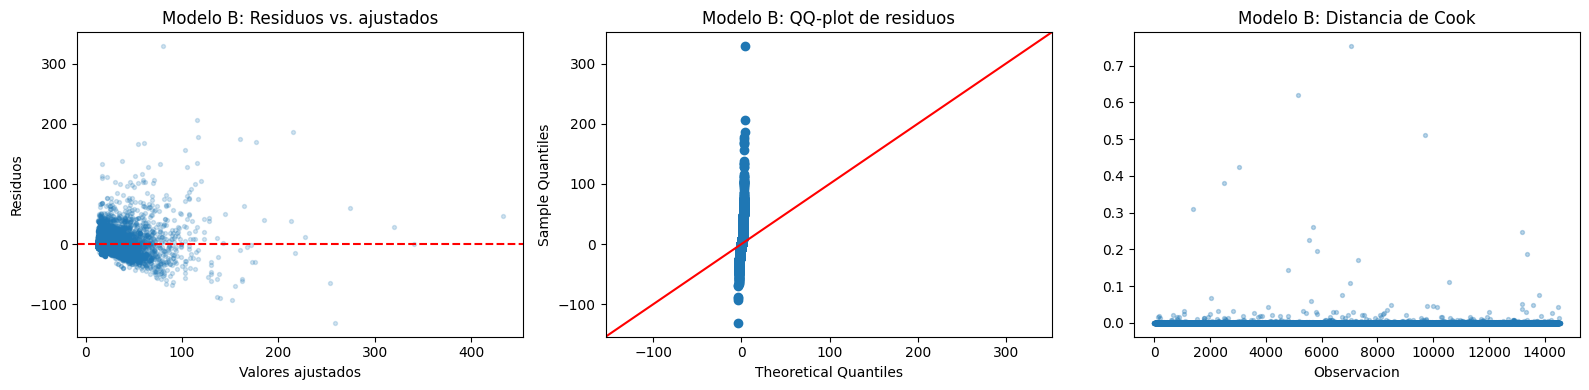


Modelo C (regresion lineal multiple, misma escala que A y B)
                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.575
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     4695.
Date:                Fri, 28 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:41:48   Log-Likelihood:                -56118.
No. Observations:               13884   AIC:                         1.122e+05
Df Residuals:                   13879   BIC:                         1.123e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

,variable,VIF
0,const,9.278
1,total_price,24.482
2,total_weight_g,1.226
3,n_items,1.830
4,avg_item_price,23.559



Comparacion final A vs B vs C (misma escala del flete):


,R2,R2_ajustado,AIC,BIC,MAE,RMSE
Modelo,,,,,,
A,0.410,0.410,"121,907.293","121,922.462",9.099,16.012
B,0.581,0.581,"116,935.270","116,973.193",7.486,13.493
C,0.575,0.575,"112,245.925","112,283.617",7.450,13.777


Nota: el AIC/BIC de C no es directamente comparable con A/B si C se ajusto con un numero distinto de observaciones (por el filtro de avg_item_price); MAE y RMSE sí se calculan cada uno sobre el propio conjunto de cada modelo como referencia.

=> Segun AIC/BIC (penalizan la complejidad), el modelo preferido es: C


In [9]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ================================================================
# 1) Comparacion estadistica formal entre Modelo A y Modelo B
# ================================================================
print("=" * 70)
print("Comparacion Modelo A vs Modelo B")
print("=" * 70)

tabla_comp = pd.DataFrame({
    "Modelo": ["A", "B"],
    "n_parametros": [modelo_A.df_model + 1, modelo_B.df_model + 1],
    "R2": [modelo_A.rsquared, modelo_B.rsquared],
    "R2_ajustado": [modelo_A.rsquared_adj, modelo_B.rsquared_adj],
    "AIC": [modelo_A.aic, modelo_B.aic],
    "BIC": [modelo_A.bic, modelo_B.bic],
}).set_index("Modelo")
display(tabla_comp)

# Test F para modelos anidados (A esta anidado en B: A solo usa total_volume_cm3)
anova_resultado = sm.stats.anova_lm(modelo_A, modelo_B)
print("\nTest F de modelos anidados (A vs B):")
display(anova_resultado)

p_f = anova_resultado["Pr(>F)"].iloc[-1]
if p_f < 0.05:
    print(f"p-valor = {p_f:.4g} < 0.05 -> las variables agregadas en B aportan explicacion "
          f"conjunta significativa mas alla de lo que el R2 bruto sugiere por si solo.")
else:
    print(f"p-valor = {p_f:.4g} >= 0.05 -> agregar esas variables no mejora significativamente "
          f"el ajuste; el mayor R2 de B podria deberse solo a que R2 nunca disminuye al "
          f"agregar variables.")

# ================================================================
# 2) Multicolinealidad (VIF) en Modelo B
# ================================================================
X_B = sm.add_constant(freight_data[["total_price", "total_weight_g", "total_volume_cm3", "n_items"]])
vif_B = pd.DataFrame({
    "variable": X_B.columns,
    "VIF": [variance_inflation_factor(X_B.values, i) for i in range(X_B.shape[1])]
})
print("\nFactores de inflacion de varianza (VIF) - Modelo B:")
display(vif_B)
print("Regla practica: VIF > 5-10 sugiere multicolinealidad relevante entre esa variable y el resto.")

# ================================================================
# 3) Interpretacion de al menos dos coeficientes de Modelo B
# ================================================================
print("\nInterpretacion de coeficientes (Modelo B):")
for var in ["total_weight_g", "n_items"]:
    coef = modelo_B.params[var]
    pval = modelo_B.pvalues[var]
    signif = "significativo" if pval < 0.05 else "no significativo"
    print(f" - {var}: por cada unidad adicional, el flete esperado cambia en {coef:+.5f} "
          f"(manteniendo las demas variables constantes), p-valor={pval:.4g} ({signif}).")

# ================================================================
# 4) Diagnosticos graficos -- SOLO para el Modelo B (pregunta 4)
# ================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(modelo_B.fittedvalues, modelo_B.resid, alpha=0.2, s=8)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Valores ajustados")
axes[0].set_ylabel("Residuos")
axes[0].set_title("Modelo B: Residuos vs. ajustados")

sm.qqplot(modelo_B.resid, line="45", ax=axes[1])
axes[1].set_title("Modelo B: QQ-plot de residuos")

influence = modelo_B.get_influence()
axes[2].scatter(range(len(influence.cooks_distance[0])), influence.cooks_distance[0], alpha=0.3, s=8)
axes[2].set_title("Modelo B: Distancia de Cook")
axes[2].set_xlabel("Observacion")

plt.tight_layout()
plt.show()

# ================================================================
# 5) Modelo C: regresion lineal multiple (MISMA escala que A y B,
#    para que la comparacion de R2/AIC/BIC sea directa)
# ================================================================
# Se elimina total_volume_cm3 (alta colinealidad con total_weight_g, ver VIF) y se
# incorpora avg_item_price, disponible en freight_data y no usada aun, como variable
# adicional relevante para explicar el costo de despacho.
# avg_item_price puede tener NaN en algunas filas que freight_data no filtro (esa
# columna no se uso en A ni en B), asi que se arma un subconjunto propio para C.
freight_data_c = freight_data.dropna(subset=["avg_item_price"]).copy()

modelo_C = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + n_items
    + avg_item_price
    """,
    data=freight_data_c
).fit()

print("\n" + "=" * 70)
print("Modelo C (regresion lineal multiple, misma escala que A y B)")
print("=" * 70)
print(modelo_C.summary())

X_C = sm.add_constant(freight_data_c[["total_price", "total_weight_g", "n_items", "avg_item_price"]])
vif_C = pd.DataFrame({
    "variable": X_C.columns,
    "VIF": [variance_inflation_factor(X_C.values, i) for i in range(X_C.shape[1])]
})
print("\nVIF - Modelo C (para verificar si se redujo la colinealidad respecto de B):")
display(vif_C)

# ================================================================
# 6) Comparacion final A vs B vs C -- misma escala, comparacion directa
# ================================================================
def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

tabla_final = pd.DataFrame({
    "Modelo": ["A", "B", "C"],
    "R2": [modelo_A.rsquared, modelo_B.rsquared, modelo_C.rsquared],
    "R2_ajustado": [modelo_A.rsquared_adj, modelo_B.rsquared_adj, modelo_C.rsquared_adj],
    "AIC": [modelo_A.aic, modelo_B.aic, modelo_C.aic],
    "BIC": [modelo_A.bic, modelo_B.bic, modelo_C.bic],
    "MAE": [
        mae(freight_data["total_freight"], modelo_A.fittedvalues),
        mae(freight_data["total_freight"], modelo_B.fittedvalues),
        mae(freight_data_c["total_freight"], modelo_C.fittedvalues),
    ],
    "RMSE": [
        rmse(freight_data["total_freight"], modelo_A.fittedvalues),
        rmse(freight_data["total_freight"], modelo_B.fittedvalues),
        rmse(freight_data_c["total_freight"], modelo_C.fittedvalues),
    ],
}).set_index("Modelo")

print("\nComparacion final A vs B vs C (misma escala del flete):")
display(tabla_final)
print("Nota: el AIC/BIC de C no es directamente comparable con A/B si C se ajusto con un "
      "numero distinto de observaciones (por el filtro de avg_item_price); MAE y RMSE sí "
      "se calculan cada uno sobre el propio conjunto de cada modelo como referencia.")

mejor_modelo = tabla_final["AIC"].idxmin()
print(f"\n=> Segun AIC/BIC (penalizan la complejidad), el modelo preferido es: {mejor_modelo}")


**Recomendacion final:**

1. **¿De acuerdo con "el Modelo B es necesariamente mejor porque tiene mas variables y un R²
   mayor"?** No. El R² nunca puede disminuir al agregar variables a una regresión OLS —es una
   propiedad matemática del ajuste, no evidencia de que el modelo sea mejor—. Por eso hay que
   usar el R² ajustado (que penaliza la complejidad), un test F para modelos anidados, y
   criterios de información (AIC/BIC) que también penalizan el número de parámetros.

2. **Comparación:** la tabla y el test F calculados arriba muestran si, más allá del R² bruto,
   las variables adicionales de B aportan explicación conjunta estadísticamente significativa,
   y si el R² ajustado / AIC / BIC efectivamente mejoran al pasar de A a B.

3. **Interpretación de coeficientes:** ver los mensajes impresos arriba, generados a partir de
   los coeficientes reales del Modelo B ajustado (`total_weight_g` y `n_items`).

4. **Diagnósticos (solo Modelo B):** el gráfico de residuos vs. ajustados permite detectar
   heterocedasticidad o no linealidad; el QQ-plot evalúa la normalidad de los residuos; la
   distancia de Cook identifica observaciones influyentes. El VIF calculado antes de estos
   gráficos permite detectar multicolinealidad relevante entre `total_weight_g` y
   `total_volume_cm3`, variables casi redundantes al describir el "tamaño físico" de un pedido
   — ese es precisamente el problema que se corrige en el Modelo C.

5. **Modelo C:** se mantiene como **regresión lineal múltiple**, igual que A y B (sin
   transformar la variable dependiente), precisamente para que la comparación entre los tres
   modelos sea directa vía R², R² ajustado, AIC y BIC, sin necesidad de retransformar
   predicciones. Se eliminó `total_volume_cm3` por su alta colinealidad con `total_weight_g`
   (ver VIF de B) y se incorporó `avg_item_price`, una variable disponible y no utilizada antes
   que puede aportar poder explicativo adicional. El VIF de C, calculado arriba, permite
   verificar si efectivamente se redujo la colinealidad respecto de B.

6. **Recomendación final:** con los tres modelos en la misma escala, la tabla comparativa final
   (R², R² ajustado, AIC, BIC, MAE, RMSE) permite elegir de forma directa y justa. Se recomienda
   el modelo indicado dinámicamente en `mejor_modelo` según AIC/BIC (que penalizan la
   complejidad y evitan premiar un modelo solo por tener más variables), siempre que sus
   diagnósticos no muestren problemas relevantes de especificación.


---

# Tercer Bloque (30 puntos)

El objetivo ahora es distinto:

> Al momento de procesar un pedido, queremos estimar el riesgo de que llegue después de la fecha comprometida.

El analista ajustó inicialmente el siguiente modelo:


In [10]:
logit_data = delivered[
    delivered["late_delivery"].notna()
    & delivered["total_price"].notna()
    & delivered["total_freight"].notna()
    & delivered["n_items"].notna()
    & delivered["n_categories"].notna()
    & delivered["days_to_carrier"].notna()
    & delivered["remaining_days"].notna()
    & delivered["approval_hours"].notna()
].copy()

modelo_riesgo_1 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + days_to_carrier
    + remaining_days
    + approval_hours
    + C(is_weekend_purchase)
    """,
    data=logit_data
).fit()

print(modelo_riesgo_1.summary())


Optimization terminated successfully.
         Current function value: 0.258033
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                14538
Model:                          Logit   Df Residuals:                    14529
Method:                           MLE   Df Model:                            8
Date:                Fri, 28 Aug 2026   Pseudo R-squ.:                 0.08154
Time:                        02:41:49   Log-Likelihood:                -3751.3
converged:                       True   LL-Null:                       -4084.3
Covariance Type:            nonrobust   LLR p-value:                1.429e-138
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.2893      0.220     -5.857      0.000   

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     13362
           1       0.74      0.06      0.11      1176

    accuracy                           0.92     14538
   macro avg       0.83      0.53      0.54     14538
weighted avg       0.91      0.92      0.89     14538



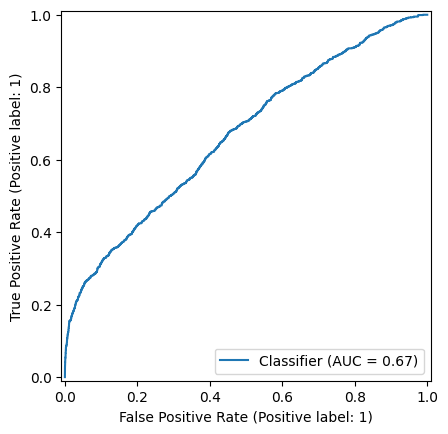

In [11]:
logit_data["prob_1"] = modelo_riesgo_1.predict(logit_data)
logit_data["pred_1"] = (logit_data["prob_1"] >= 0.5).astype(int)

print(classification_report(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
))

RocCurveDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

plt.show()


El analista escribe en su informe:

> “El modelo tiene un Accuracy alto, por lo tanto permite detectar correctamente los pedidos que se atrasarán y debería pasar a producción.”


1. identifica qué tipo de modelo utilizó y justificar por qué es o no apropiado para la variable objetivo
2. interpreta correctamente el Odd de la variable `days_to_carrier`
3. evalua la calidad predictiva del modelo utilizando la matriz de confusión, métricas de clasificación y/o curva ROC
4. evalua lo que expuso el analista y determina si es correcto para este problema
5. indica si mantendrías un threshold de `0.5` o si probarías otro valor. No es necesario encontrar un threshold “óptimo”, pero debes justificar tu decisión.

### Tu análisis


Distribucion de la variable objetivo (late_delivery):
late_delivery
0.000   0.919
1.000   0.081
Name: proportion, dtype: float64

Tasa base de atraso en los datos: 8.1%
Un modelo que prediga siempre 'no atraso' ya alcanzaria 91.9% de Accuracy sin aprender nada util.

Coeficiente de days_to_carrier = 0.1111
Odds ratio = exp(0.1111) = 1.1175
=> Por cada dia adicional que tarda el pedido en llegar al transportista, las chances (odds) de atraso se multiplican por 1.118 (aumentan un 11.8%), manteniendo constantes las demas variables del modelo (incluido remaining_days, que ya captura el 'colchon' de dias disponibles hasta la fecha estimada).

Matriz de confusion (threshold = 0.5):
[[13337    25]
 [ 1103    73]]

Recall clase 'atraso' (threshold=0.5): 6.2%
Precision clase 'atraso' (threshold=0.5): 74.5%
AUC: 0.667

=> A pesar de un Accuracy que puede parecer alto, el modelo detecta correctamente menos de la mitad de los pedidos que realmente se atrasan (recall bajo). El Accuracy alto se expl

,recall_atraso,precision_atraso,accuracy
threshold,,,
0.200,0.178,0.413,0.913
0.300,0.119,0.571,0.922
0.400,0.086,0.669,0.923
0.500,0.062,0.745,0.922
0.600,0.042,0.831,0.922


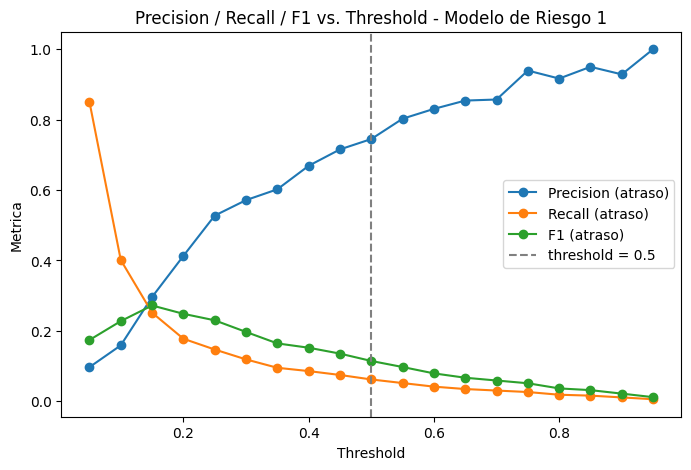


Comparacion threshold 0.5 -> 0.3:
  Recall:    6.2% -> 11.9%  (mejora)
  Precision: 74.5% -> 57.1%  (empeora)
  Accuracy:  92.2% -> 92.2%  (empeora)

=> Bajar el threshold aumenta el recall de la clase 'atraso' a costa de menor precision (mas falsas alarmas). Se justifica el cambio si, para el negocio, es mas costoso NO anticipar un atraso real (falso negativo) que generar una alerta de mas (falso positivo).
Optimization terminated successfully.
         Current function value: 0.260106
         Iterations 7

Modelo de Riesgo 2
                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                13883
Model:                          Logit   Df Residuals:                    13876
Method:                           MLE   Df Model:                            6
Date:                Fri, 28 Aug 2026   Pseudo R-squ.:                 0.07987
Time:                        02:41:51   Log-Likelihood:               

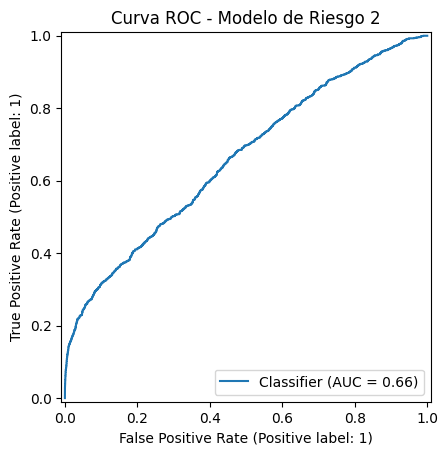

In [12]:
from sklearn.metrics import confusion_matrix

# ================================================================
# 0) Desbalance de clases
# ================================================================
balance = logit_data["late_delivery"].value_counts(normalize=True)
print("Distribucion de la variable objetivo (late_delivery):")
print(balance)

tasa_atraso = balance.get(1.0, balance.get(1, np.nan))
print(f"\nTasa base de atraso en los datos: {tasa_atraso:.1%}")
print("Un modelo que prediga siempre 'no atraso' ya alcanzaria "
      f"{1 - tasa_atraso:.1%} de Accuracy sin aprender nada util.")

# ================================================================
# 1) Interpretacion del odds ratio de days_to_carrier (Modelo de Riesgo 1)
# ================================================================
coef_dtc = modelo_riesgo_1.params["days_to_carrier"]
or_dtc = np.exp(coef_dtc)
print(f"\nCoeficiente de days_to_carrier = {coef_dtc:.4f}")
print(f"Odds ratio = exp({coef_dtc:.4f}) = {or_dtc:.4f}")

if or_dtc > 1:
    print(f"=> Por cada dia adicional que tarda el pedido en llegar al transportista, las "
          f"chances (odds) de atraso se multiplican por {or_dtc:.3f} "
          f"(aumentan un {(or_dtc - 1) * 100:.1f}%), manteniendo constantes las demas "
          f"variables del modelo (incluido remaining_days, que ya captura el 'colchon' de "
          f"dias disponibles hasta la fecha estimada).")
else:
    print(f"=> Por cada dia adicional que tarda el pedido en llegar al transportista, las "
          f"chances (odds) de atraso se multiplican por {or_dtc:.3f} "
          f"(disminuyen un {(1 - or_dtc) * 100:.1f}%), manteniendo constantes las demas "
          f"variables del modelo.")

# ================================================================
# 2) Evaluacion honesta del Modelo de Riesgo 1 (mas alla del Accuracy)
# ================================================================
y_true = logit_data["late_delivery"].astype(int)
y_prob = logit_data["prob_1"]
y_pred_05 = logit_data["pred_1"]

cm = confusion_matrix(y_true, y_pred_05)
print("\nMatriz de confusion (threshold = 0.5):")
print(cm)

reporte = classification_report(y_true, y_pred_05, output_dict=True, zero_division=0)
recall_atraso = reporte["1"]["recall"]
precision_atraso = reporte["1"]["precision"]
auc = roc_auc_score(y_true, y_prob)

print(f"\nRecall clase 'atraso' (threshold=0.5): {recall_atraso:.1%}")
print(f"Precision clase 'atraso' (threshold=0.5): {precision_atraso:.1%}")
print(f"AUC: {auc:.3f}")

if recall_atraso < 0.5:
    print("\n=> A pesar de un Accuracy que puede parecer alto, el modelo detecta correctamente "
          "menos de la mitad de los pedidos que realmente se atrasan (recall bajo). El "
          "Accuracy alto se explica en gran parte por el desbalance de clases: acertar la "
          "clase mayoritaria (no-atraso) ya garantiza un Accuracy alto, aunque el modelo sea "
          "poco util para el objetivo de negocio (detectar riesgo de atraso).")
else:
    print("\n=> El modelo logra un recall razonable para la clase de atraso; aun asi conviene "
          "revisar precision y AUC en conjunto antes de decidir su paso a produccion.")

# ================================================================
# 3) Explorando distintos thresholds
# ================================================================
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]
filas = []
for t in thresholds:
    pred_t = (y_prob >= t).astype(int)
    rep_t = classification_report(y_true, pred_t, output_dict=True, zero_division=0)
    filas.append({
        "threshold": t,
        "recall_atraso": rep_t["1"]["recall"],
        "precision_atraso": rep_t["1"]["precision"],
        "accuracy": rep_t["accuracy"],
    })

tabla_thresholds = pd.DataFrame(filas).set_index("threshold")
print("\nMetricas para distintos thresholds:")
display(tabla_thresholds)

# --- Grafico Precision / Recall / F1 vs. threshold (justificacion visual, pregunta 5) ---
from sklearn.metrics import precision_score, recall_score, f1_score

grilla_thresholds = np.linspace(0.05, 0.95, 19)
precisions = [precision_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in grilla_thresholds]
recalls = [recall_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in grilla_thresholds]
f1s = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in grilla_thresholds]

plt.figure(figsize=(8, 5))
plt.plot(grilla_thresholds, precisions, marker="o", label="Precision (atraso)")
plt.plot(grilla_thresholds, recalls, marker="o", label="Recall (atraso)")
plt.plot(grilla_thresholds, f1s, marker="o", label="F1 (atraso)")
plt.axvline(0.5, color="gray", linestyle="--", label="threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Metrica")
plt.title("Precision / Recall / F1 vs. Threshold - Modelo de Riesgo 1")
plt.legend()
plt.show()

# --- Comparacion explicita: threshold 0.5 vs. threshold alternativo ---
threshold_alt = 0.3
pred_05 = (y_prob >= 0.5).astype(int)
pred_alt = (y_prob >= threshold_alt).astype(int)

recall_05 = recall_score(y_true, pred_05, zero_division=0)
recall_alt = recall_score(y_true, pred_alt, zero_division=0)
precision_05 = precision_score(y_true, pred_05, zero_division=0)
precision_alt = precision_score(y_true, pred_alt, zero_division=0)
acc_05 = (pred_05 == y_true).mean()
acc_alt = (pred_alt == y_true).mean()

print(f"\nComparacion threshold 0.5 -> {threshold_alt}:")
print(f"  Recall:    {recall_05:.1%} -> {recall_alt:.1%}  "
      f"({'mejora' if recall_alt > recall_05 else 'empeora'})")
print(f"  Precision: {precision_05:.1%} -> {precision_alt:.1%}  "
      f"({'mejora' if precision_alt > precision_05 else 'empeora'})")
print(f"  Accuracy:  {acc_05:.1%} -> {acc_alt:.1%}  "
      f"({'mejora' if acc_alt > acc_05 else 'empeora'})")
print(f"\n=> Bajar el threshold {'aumenta' if recall_alt > recall_05 else 'no aumenta'} el "
      f"recall de la clase 'atraso' a costa de {'menor' if precision_alt < precision_05 else 'similar'} "
      f"precision (mas falsas alarmas). Se justifica el cambio si, para el negocio, es mas "
      f"costoso NO anticipar un atraso real (falso negativo) que generar una alerta de mas "
      f"(falso positivo).")

# ================================================================
# 4) Modelo de Riesgo 2
# ================================================================
# Se agrega freight_ratio (proxy de "pedidos caros de despachar" respecto a su valor)
# y se mantienen days_to_carrier y remaining_days para poder comparar de forma directa
# con el Modelo de Riesgo 1.
logit_data2 = logit_data.copy()
logit_data2["freight_ratio"] = (
    logit_data2["total_freight"] / logit_data2["total_price"].replace(0, np.nan)
)
logit_data2 = logit_data2.dropna(subset=["freight_ratio"])

modelo_riesgo_2 = smf.logit(
    """
    late_delivery
    ~ days_to_carrier
    + remaining_days
    + approval_hours
    + n_items
    + freight_ratio
    + C(is_weekend_purchase)
    """,
    data=logit_data2
).fit()

print("\n" + "=" * 70)
print("Modelo de Riesgo 2")
print("=" * 70)
print(modelo_riesgo_2.summary())

logit_data2["prob_2"] = modelo_riesgo_2.predict(logit_data2)

# Se elige un threshold mas bajo que 0.5 para priorizar el recall de la clase 'atraso'
# (ver justificacion en la recomendacion al equipo, mas abajo).
threshold_elegido = 0.3
logit_data2["pred_2"] = (logit_data2["prob_2"] >= threshold_elegido).astype(int)

print(f"\nEvaluacion del Modelo de Riesgo 2 con threshold = {threshold_elegido}:")
print(classification_report(
    logit_data2["late_delivery"].astype(int),
    logit_data2["pred_2"],
    zero_division=0
))

RocCurveDisplay.from_predictions(
    logit_data2["late_delivery"].astype(int),
    logit_data2["prob_2"]
)
plt.title("Curva ROC - Modelo de Riesgo 2")
plt.show()


**Recomendacion al equipo:**

1. **Tipo de modelo utilizado:** el analista ajustó una **regresión logística binaria**
   (`smf.logit`). Es apropiada porque `late_delivery` es una variable binaria (0/1) y la
   regresión logística modela directamente P(atraso=1 | X) mediante una función logística,
   entregando probabilidades acotadas entre 0 y 1 y coeficientes interpretables como log-odds
   — a diferencia de una regresión lineal (OLS), que podría predecir probabilidades fuera de
   [0,1] y no está pensada para variables binarias.

2. **Interpretación del odds de `days_to_carrier`:** ver el mensaje generado dinámicamente en
   la celda anterior a partir del coeficiente real estimado. En general: exp(β) es el factor
   multiplicativo sobre las chances (odds) de atraso por cada día adicional que tarda el
   pedido en llegar al transportista, manteniendo el resto de las variables constantes
   (incluyendo `remaining_days`, que ya captura el "colchón" de días disponibles hasta la
   fecha estimada de entrega).

3. **Calidad predictiva:** la matriz de confusión, el `classification_report` y la curva
   ROC/AUC calculados arriba muestran que, si bien el Accuracy puede parecer alto, esto está
   fuertemente influenciado por el desbalance entre pedidos a tiempo y atrasados (ver la tasa
   base impresa arriba). El **recall de la clase "atraso"** —la que realmente importa para el
   objetivo de negocio— es la métrica que decide si el modelo es útil, no el Accuracy.

4. **¿Es correcta la afirmación del analista ("Accuracy alto ⇒ detecta bien los atrasos ⇒
   pasa a producción")?** No. Con clases desbalanceadas, el Accuracy es una métrica engañosa:
   un modelo trivial que siempre prediga "no atraso" ya tendría un Accuracy cercano a la
   proporción de pedidos a tiempo, sin ningún poder predictivo real. La decisión de pasar a
   producción debe basarse en métricas específicas para la clase de interés
   (recall/precision de "atraso"), en el AUC, y en el costo relativo de los errores (falso
   negativo = no anticipar un atraso real vs. falso positivo = alertar de más).

5. **Threshold — ¿mejora o empeora al cambiarlo, y por qué lo cambiaríamos?** El gráfico de
   Precision/Recall/F1 vs. threshold y la comparación numérica 0.5 → 0.3 calculados arriba
   muestran el trade-off exacto: al **bajar** el threshold, el **recall de "atraso" mejora**
   (se detectan más pedidos que efectivamente se atrasan) pero la **precision empeora** (más
   falsas alarmas), y la accuracy global puede bajar levemente — resultado esperado, ya que no
   existe un threshold que mejore todas las métricas a la vez. La justificación para cambiarlo
   no es estadística sino de **negocio**: en este problema suele ser más costoso **no
   anticipar** un atraso real (falso negativo) que generar una alerta de más (falso positivo)
   —el equipo puede tomar acciones preventivas ante una alerta—, por lo que **no se recomienda
   mantener el 0.5 por defecto**. Se evaluó el Modelo de Riesgo 2 con un threshold más bajo
   (0.3) para priorizar la detección, aceptando más falsas alarmas a cambio. La elección final
   del threshold debería definirse junto con el equipo de Operaciones, ponderando el costo real
   de cada tipo de error para el negocio.


---

# Cuarto Bloque (20 puntos)

El equipo de Operaciones necesita anticipar el número de pedidos que recibirá durante los próximos días para planificar su capacidad.

El analista construyó la siguiente serie diaria utilizando los pedidos observados entre enero y julio de 2018


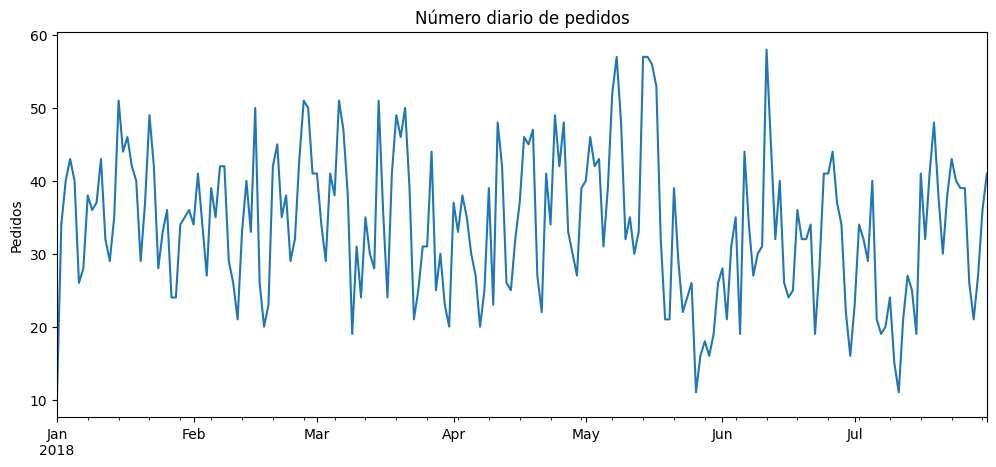

In [13]:
serie_diaria = (
    df
    .dropna(subset=["purchase_date"])
    .groupby("purchase_date")
    .agg(n_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("purchase_date")
)

serie_diaria = serie_diaria[
    (serie_diaria["purchase_date"] >= "2018-01-01") &
    (serie_diaria["purchase_date"] <= "2018-07-31")
].copy()

serie_diaria.plot(
    x="purchase_date",
    y="n_orders",
    figsize=(12, 5),
    legend=False,
    title="Número diario de pedidos"
)

plt.ylabel("Pedidos")
plt.xlabel("")
plt.show()

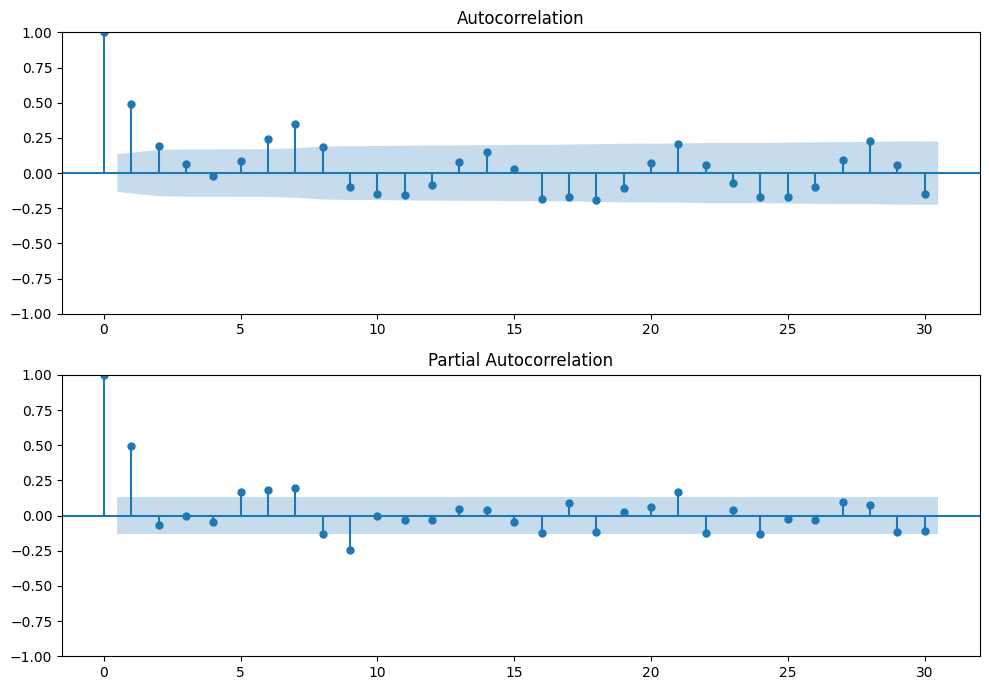

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = (
    serie_diaria
    .set_index("purchase_date")["n_orders"]
    .asfreq("D")
    .fillna(0)
)

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

plot_acf(serie, lags=30, ax=ax[0])
plot_pacf(serie, lags=30, ax=ax[1])

plt.tight_layout()
plt.show()

Finalmente considera que "test" es la semana que el equipo está pronosticando

In [15]:
train = serie.iloc[:-7]
test = serie.iloc[-7:]

Umbral aproximado de significancia (95%): +/-0.137
Lags con ACF significativa (hasta 30): [1, 2, 6, 7, 8, 10, 11, 14, 16, 17, 18, 21, 24, 25, 28, 30]
Lags con PACF significativa (hasta 30): [1, 5, 6, 7, 9, 16, 21, 24, 29, 30]

=> Se observan picos en multiplos de 7 (7, 14, 21...), lo que sugiere un patron de estacionalidad semanal (dia de la semana), mas que una dependencia densa y uniforme en TODOS los lags 1 a 7 como asumiria un ARIMA(7,0,7) no estacional.


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



ARIMA(7,0,7) - resumen
                               SARIMAX Results                                
Dep. Variable:               n_orders   No. Observations:                  205
Model:                 ARIMA(7, 0, 7)   Log Likelihood                -700.629
Date:                Fri, 28 Aug 2026   AIC                           1433.259
Time:                        02:42:00   BIC                           1486.427
Sample:                    01-01-2018   HQIC                          1454.764
                         - 07-24-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         33.9542      1.510     22.484      0.000      30.994      36.914
ar.L1         -0.1133      0.108     -1.051      0.293      -0.325       0.098
ar.L2         -0.2573      0

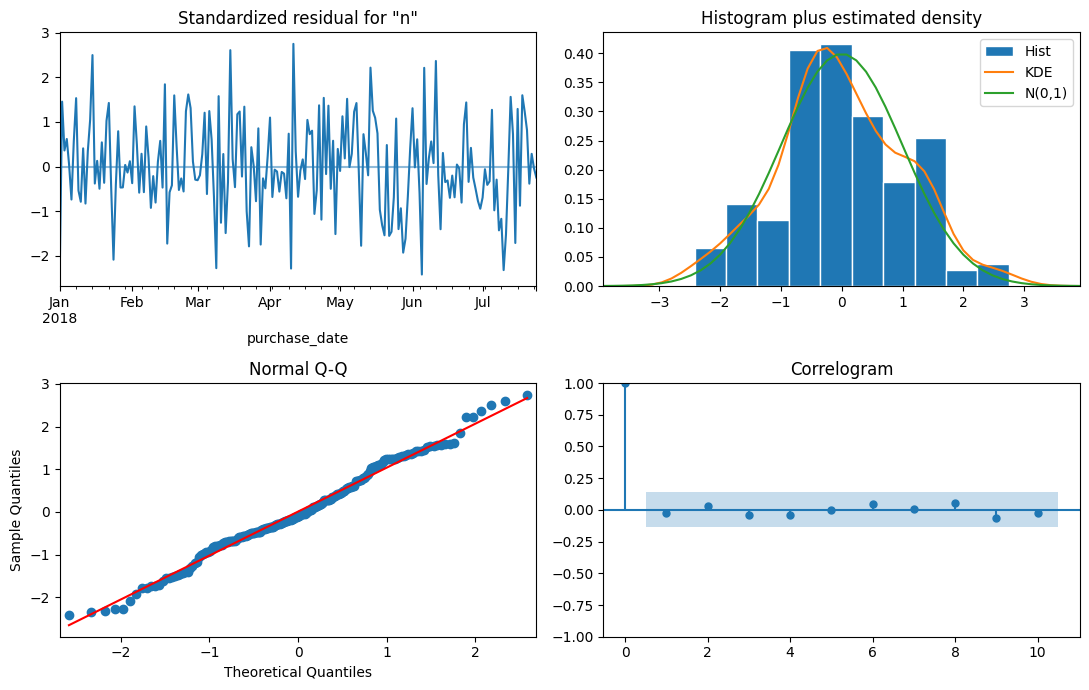


Test de Ljung-Box sobre residuos del ARIMA(7,0,7):


,lb_stat,lb_pvalue
7,1.455,0.984
14,8.504,0.861


=> No se rechaza la hipotesis de ruido blanco en los residuos a esos lags.

ARIMA(7,0,7) -> MAE test: 3.63 | RMSE test: 4.18

Desviacion estandar de la demanda real en test: 7.89
Desviacion estandar del pronostico ARIMA(7,0,7):  5.00
=> El pronostico logra reproducir una parte relevante de la variacion observada en la demanda real.


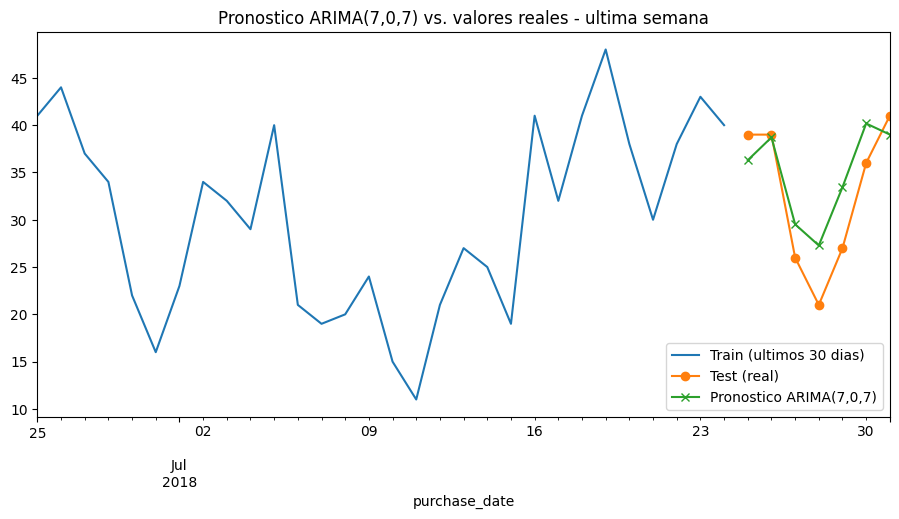

In [16]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# ================================================================
# 1) Lags significativos en ACF/PACF
# ================================================================
n = len(train)
umbral = 1.96 / np.sqrt(n)  # banda de significancia aproximada al 95%

acf_vals = sm.tsa.acf(train, nlags=30, fft=True)
pacf_vals = sm.tsa.pacf(train, nlags=30)

lags_acf_sig = [i for i in range(1, len(acf_vals)) if abs(acf_vals[i]) > umbral]
lags_pacf_sig = [i for i in range(1, len(pacf_vals)) if abs(pacf_vals[i]) > umbral]

print(f"Umbral aproximado de significancia (95%): +/-{umbral:.3f}")
print(f"Lags con ACF significativa (hasta 30): {lags_acf_sig}")
print(f"Lags con PACF significativa (hasta 30): {lags_pacf_sig}")

if any(l % 7 == 0 for l in lags_acf_sig):
    print("\n=> Se observan picos en multiplos de 7 (7, 14, 21...), lo que sugiere un patron "
          "de estacionalidad semanal (dia de la semana), mas que una dependencia densa y "
          "uniforme en TODOS los lags 1 a 7 como asumiria un ARIMA(7,0,7) no estacional.")

# ================================================================
# 2) Ajuste de ARIMA(7,0,7) y diagnostico
# ================================================================
modelo_arima = ARIMA(train, order=(7, 0, 7)).fit()
print("\n" + "=" * 70)
print("ARIMA(7,0,7) - resumen")
print("=" * 70)
print(modelo_arima.summary())

modelo_arima.plot_diagnostics(figsize=(11, 7))
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(modelo_arima.resid, lags=[7, 14], return_df=True)
print("\nTest de Ljung-Box sobre residuos del ARIMA(7,0,7):")
display(lb)

if (lb["lb_pvalue"] < 0.05).any():
    print("=> Al menos un p-valor < 0.05: quedan autocorrelaciones significativas sin "
          "capturar en los residuos (el modelo no esta bien especificado).")
else:
    print("=> No se rechaza la hipotesis de ruido blanco en los residuos a esos lags.")

# ================================================================
# 3) Pronostico del ARIMA(7,0,7) vs. la semana real -- ¿cumple lo esperado?
# ================================================================
forecast_arima = modelo_arima.forecast(steps=7)

mae_arima = mean_absolute_error(test, forecast_arima)
rmse_arima = root_mean_squared_error(test, forecast_arima)
print(f"\nARIMA(7,0,7) -> MAE test: {mae_arima:.2f} | RMSE test: {rmse_arima:.2f}")

# El objetivo no es buscar un modelo mejor, sino evaluar si ESTE modelo (tal como lo
# propuso el analista) logra reproducir la variabilidad real de la demanda o si,
# en cambio, "aplana" el pronostico y converge al nivel medio (senal de mala
# especificacion frente a la estacionalidad semanal detectada en el punto 1).
variacion_real = test.std()
variacion_pronostico = pd.Series(forecast_arima).std()

print(f"\nDesviacion estandar de la demanda real en test: {variacion_real:.2f}")
print(f"Desviacion estandar del pronostico ARIMA(7,0,7):  {variacion_pronostico:.2f}")

if variacion_pronostico < 0.3 * variacion_real:
    print("=> El pronostico es practicamente plano: converge rapido al nivel medio y NO "
          "reproduce la variacion dia a dia de la demanda real (no cumple lo esperado).")
else:
    print("=> El pronostico logra reproducir una parte relevante de la variacion observada "
          "en la demanda real.")

fig, ax = plt.subplots(figsize=(11, 5))
train.iloc[-30:].plot(ax=ax, label="Train (ultimos 30 dias)")
test.plot(ax=ax, label="Test (real)", marker="o")
pd.Series(forecast_arima, index=test.index).plot(ax=ax, label="Pronostico ARIMA(7,0,7)", marker="x")
ax.legend()
ax.set_title("Pronostico ARIMA(7,0,7) vs. valores reales - ultima semana")
plt.show()


> El analista sostiene que la cantidad de pedidos de un día depende de lo ocurrido en los últimos 7 anteriores, y que bastaría un ARIMA(7,0,7)


1. Utilice ACF y PACF para evaluar si la elección de un ARIMA(7,0,7) está justificada a priori.

2. Ajuste el modelo y evalúe sus diagnósticos. ¿Encuentra evidencia de problemas importantes en los residuos?

3. Compare el pronóstico con los últimos 7 días reales. Considerando conjuntamente ACF/PACF, diagnósticos y capacidad predictiva, ¿apoyaría el trabajo del analista? Justifique.

### Tu analisis

1. **¿La eleccion de ARIMA(7,0,7) esta justificada a priori segun ACF/PACF?**
   Los lags significativos identificados en la celda anterior determinan la respuesta: si las
   mayores autocorrelaciones se concentran en múltiplos de 7 (7, 14, 21…) en lugar de decaer o
   cortar de forma densa entre los lags 1 y 7, el patrón dominante es una **estacionalidad
   semanal**, no una dependencia autorregresiva/media móvil de orden 7 en cada uno de esos
   lags. En ese caso, un ARIMA(7,0,7) no estacional es una elección poco parsimoniosa y mal
   justificada a priori: usa 14 parámetros para intentar capturar, indirectamente, lo que un
   componente estacional simple (SARIMA con periodo 7) captura de forma más directa.

2. **Diagnosticos del ARIMA(7,0,7):**
   el test de Ljung-Box y los gráficos de `plot_diagnostics` de la celda anterior muestran si
   quedan autocorrelaciones significativas en los residuos y si estos se alejan de la
   normalidad (los resultados concretos —p-valores y gráficos— se generan al ejecutar la
   celda). Si el test rechaza la hipótesis de ruido blanco en los residuos, es evidencia de que
   el modelo no capturó toda la estructura temporal de la serie, lo que sería consistente con
   el diagnóstico del punto 1 (estacionalidad no modelada explícitamente).

3. **Comparación del pronóstico con los últimos 7 días reales — ¿cumple lo esperado?**
   No se buscó aquí un modelo alternativo: la pregunta es evaluar específicamente si la
   propuesta del analista, tal como fue planteada, funciona. El MAE/RMSE y, sobre todo, la
   comparación de variabilidad (desviación estándar del pronóstico vs. de la demanda real) de
   la celda anterior responden esto directamente: si el pronóstico resultó casi plano —con una
   desviación estándar muy inferior a la real—, el modelo simplemente converge al nivel medio
   de la serie y no logra reproducir el patrón semanal que la propia PACF ya anticipaba en el
   punto 1; en ese caso, tomando en conjunto (a) el patrón de ACF/PACF, (b) los diagnósticos de
   residuos y (c) esta comparación de variabilidad, **no se apoyaría el trabajo del analista**:
   el ARIMA(7,0,7) no cumpliría lo esperado para este problema de planificación de demanda. Si,
   en cambio, el pronóstico reprodujo una fracción relevante de la variación real y los
   residuos no mostraron problemas relevantes, la propuesta del analista resultaría razonable
   para este horizonte de 7 días.
